# Beyond the Chains
## 04 — Historical NFL Team-Season Offensive Performance (2000–2025)

### Research Objective

Investigate and compare the rushing and passing performance of individual NFL teams across 26 regular seasons.

### Research Questions

1. Which NFL teams recorded the highest and lowest average rushing and passing yards per game?
2. How did individual teams' offensive production change over time?
3. Which teams exhibited the greatest consistency in rushing and passing production?
4. Which teams demonstrated strong performance in both rushing and passing?
5. How do individual team performances compare with league-wide averages?

### Statistical Methods

- Grouped descriptive statistics
- Measures of central tendency and dispersion
- Historical trend analysis
- Team rankings and percentiles
- Comparative data visualization
- Exploratory correlation analysis

### Observational Unit

The source data contains one observation per team per game.

Aggregating by season and team creates a team-season dataset, where each observation summarizes a team's performance across its regular-season games.



First we will start with 2025 to get a brief look at how it looks

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

print(sys.executable)

from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "exploratory_analysis":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent

team_stats = pd.read_parquet(
    ROOT / "data" / "processed" / "team_stats_2000_2025.parquet"
)

# Regular-season observations only
offense = team_stats.loc[
    team_stats["season_type"] == "REG",
    [
        "season",
        "week",
        "game_id",
        "team",
        "opponent_team",
        "rushing_yards",
        "passing_yards"
    ]
].copy()

print("Team-game observations:", len(offense))
display(offense.head())


/Users/edwardhutchens/Documents/beyond-the-chains-analytics/.venv/bin/python
Team-game observations: 13418


,season,week,game_id,team,opponent_team,rushing_yards,passing_yards
0,2000,1,2000_01_ARI_NYG,ARI,NYG,43,318
1,2000,1,2000_01_SF_ATL,ATL,SF,95,264
2,2000,1,2000_01_BAL_PIT,BAL,PIT,140,199
3,2000,1,2000_01_TEN_BUF,BUF,TEN,129,174
4,2000,1,2000_01_CAR_WAS,CAR,WAS,112,183


In [2]:
# constructing our team-season data 

team_stats.groupby(["season", "team"])



#calculating each team's rushign and passing peformances across its games

team_season = (
    offense.groupby(["season", "team"])
    .agg(
        games=("game_id", "nunique"),

        rushing_mean=("rushing_yards", "mean"),
        rushing_median=("rushing_yards", "median"),
        rushing_std=("rushing_yards", "std"),
        rushing_min=("rushing_yards", "min"),
        rushing_max=("rushing_yards", "max"),

        passing_mean=("passing_yards", "mean"),
        passing_median=("passing_yards", "median"),
        passing_std=("passing_yards", "std"),
        passing_min=("passing_yards", "min"),
        passing_max=("passing_yards", "max")
    )
    .reset_index()
)

display(team_season.round(2))


,season,team,games,rushing_mean,rushing_median,rushing_std,rushing_min,rushing_max,passing_mean,passing_median,passing_std,passing_min,passing_max
0,2000,ARI,16,79.88,80.0,36.47,28,146,217.38,212.0,51.21,144,318
1,2000,ATL,16,75.88,71.5,31.42,13,131,197.88,186.5,48.12,126,264
2,2000,BAL,16,137.44,126.5,57.60,56,250,193.88,194.0,62.73,70,290
3,2000,BUF,15,123.07,120.0,43.39,66,213,247.60,253.0,75.26,75,366
4,2000,CAR,16,74.12,78.5,40.25,10,133,240.62,238.0,60.38,161,364
...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,2025,SEA,17,123.29,122.0,41.43,50,198,239.00,244.0,63.00,128,341
826,2025,SF,17,106.88,91.0,45.55,48,200,254.00,279.0,68.97,127,347
827,2025,TB,17,114.53,104.0,45.64,41,202,220.88,215.0,76.26,103,379
828,2025,TEN,17,93.47,82.0,38.45,39,184,190.65,194.0,57.85,108,265


In [3]:
#ranking each team within each season


#for example, we are testing it with season 2025

season_2025 = team_season.loc[
    team_season["season"] == 2025 # annotating to remember what it is for. creates a Boolean condition in whihc it only selects where the condition is True. in this case if the season is 2025 or not
].copy()

season_2025["rushing_rank"] = (   # creates a new column in where it ranks and it assings a rank to each observation. 
    season_2025["rushing_mean"]
    .rank(ascending=False, method="min")
)

season_2025["passing_rank"] = (
    season_2025["passing_mean"]
    .rank(ascending=False, method="min")
)

display(
    season_2025[
        [
            "team",
            "games",
            "rushing_mean",
            "rushing_rank",
            "rushing_median",
            "rushing_std",
            "passing_mean",
            "passing_rank",
            "passing_median",
            "passing_std"
        ]
    ]
    .sort_values("passing_rank")
    .round(2)
)


,team,games,rushing_mean,rushing_rank,rushing_median,rushing_std,passing_mean,passing_rank,passing_median,passing_std
806,DAL,17,125.65,9.0,123.0,38.37,278.53,1.0,268.0,60.17
814,LA,17,126.59,7.0,124.0,46.14,276.88,2.0,273.0,83.78
808,DET,17,120.06,14.0,109.0,65.43,268.65,3.0,261.0,57.96
819,NE,17,128.88,6.0,119.0,57.41,262.29,4.0,270.0,47.82
798,ARI,17,93.12,31.0,89.0,37.05,256.12,5.0,258.0,69.64
826,SF,17,106.88,24.0,91.0,45.55,254.00,6.0,279.0,68.97
804,CIN,17,93.59,29.0,100.0,41.59,249.65,7.0,236.0,89.18
811,IND,17,118.06,17.0,96.0,64.58,240.29,8.0,255.0,58.78
825,SEA,17,123.29,10.0,122.0,41.43,239.00,9.0,244.0,63.00
820,NO,17,94.29,28.0,84.0,35.67,236.88,10.0,239.0,57.14


In [4]:

# Team-season rushing and passing variability — 2025

display(
    season_2025[
        [
            "team",
            "rushing_mean",
            "rushing_std",
            "passing_mean",
            "passing_std"
        ]
    ]
    .sort_values("passing_std")
    .round(2)
)


,team,rushing_mean,rushing_std,passing_mean,passing_std
810,HOU,108.94,31.52,232.71,43.51
800,BAL,156.59,66.70,192.82,43.94
829,WAS,134.71,44.70,195.82,45.39
819,NE,128.88,57.41,262.29,47.82
803,CHI,144.47,64.40,234.76,48.20
812,JAX,115.06,41.52,236.82,49.60
824,PIT,103.29,52.81,213.65,49.79
817,MIA,120.24,55.59,195.41,55.00
820,NO,94.29,35.67,236.88,57.14
828,TEN,93.47,38.45,190.65,57.85


### 2025 NFL Team-Season Offensive Production

The analysis compares average rushing and passing yards per game across all 32 NFL teams during the 2025 regular season.

Each observation represents one team's average offensive production across 17 regular-season games.

The **Dallas Cowboys** recorded the highest average passing production at 278.53 yards per game, while the **Buffalo Bills** led in rushing production with 159.65 yards per game.

Several teams demonstrated contrasting offensive profiles. Baltimore ranked second in rushing yards per game but 28th in passing, while Arizona ranked fifth in passing but 31st in rushing.

Conversely, New England ranked among the top six teams in both categories, suggesting relatively high production across both offensive dimensions.

The scatterplot illustrates substantial differences in team offensive production, with teams occupying different regions based on their rushing and passing averages.

**Interpretation:** The findings demonstrate that strong production in one offensive category does not necessarily correspond to strong production in the other. However, these results do not establish whether rushing and passing production are statistically correlated.

Furthermore, offensive yardage alone does not measure overall efficiency. Additional statistics, including scoring, EPA, success rates, and turnovers, will be necessary for a more comprehensive evaluation of offensive effectiveness.

In [6]:
league_rushing = season_2025["rushing_mean"].mean()
league_passing = season_2025["passing_mean"].mean()

print(f"2025 League Average Rushing Yards/Game: {league_rushing:.2f}")
print(f"2025 League Average Passing Yards/Game: {league_passing:.2f}")

2025 League Average Rushing Yards/Game: 116.94
2025 League Average Passing Yards/Game: 225.02


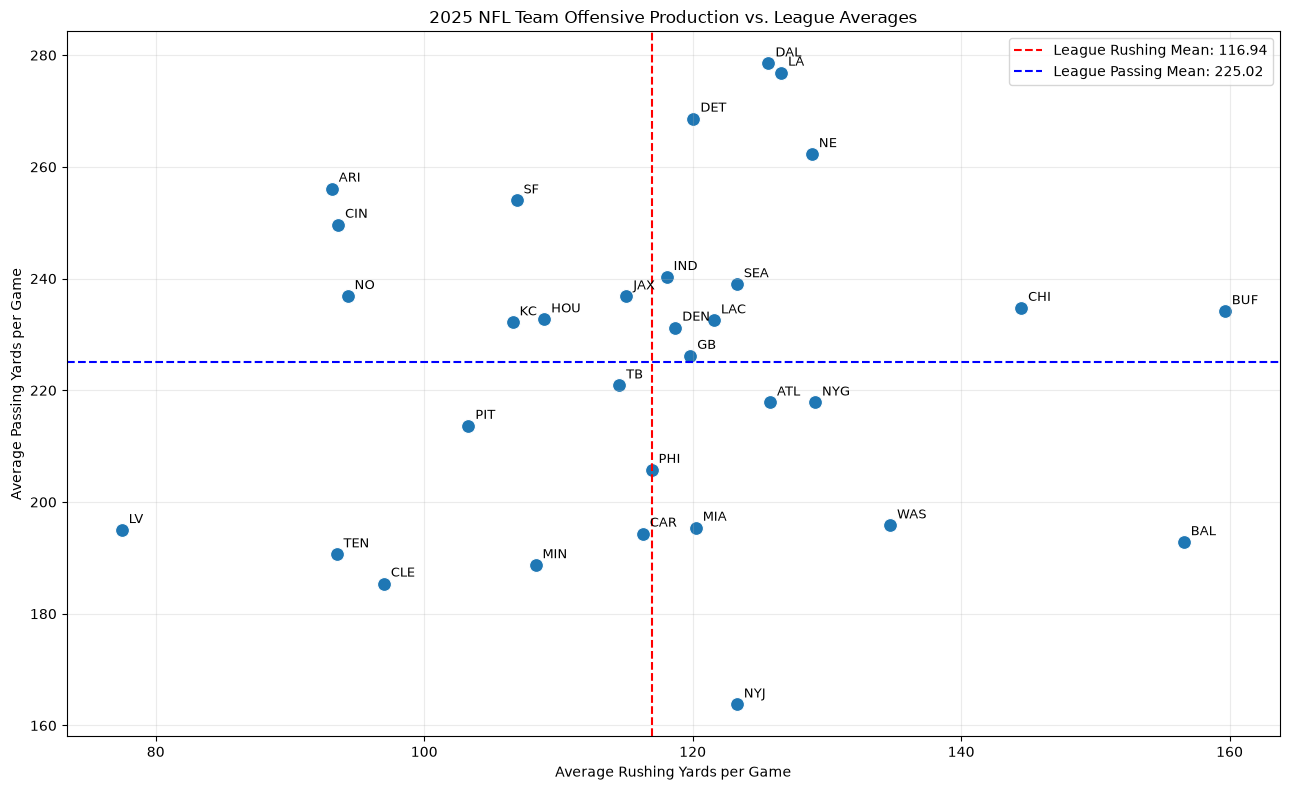

In [7]:
# plot to compare against other teams in this season

plt.figure(figsize=(13, 8))

# Scatterplot of team-season averages
sns.scatterplot(
    data=season_2025,
    x="rushing_mean",
    y="passing_mean",
    s=100
)

# Label each team
for _, row in season_2025.iterrows():
    plt.annotate(
        row["team"],
        (row["rushing_mean"], row["passing_mean"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# League-wide reference lines
plt.axvline(
    league_rushing,
    color="red",
    linestyle="--",
    label=f"League Rushing Mean: {league_rushing:.2f}"
)

plt.axhline(
    league_passing,
    color="blue",
    linestyle="--",
    label=f"League Passing Mean: {league_passing:.2f}"
)

plt.title("2025 NFL Team Offensive Production vs. League Averages")
plt.xlabel("Average Rushing Yards per Game")
plt.ylabel("Average Passing Yards per Game")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()




### Classification of NFL Team Offensive Profiles (2025)

NFL teams were classified into four offensive profiles based on their average rushing and passing yards per game relative to the 2025 league-wide averages.

- **Above Average in Both:** Teams producing above-average rushing and passing yards per game, indicating relatively high production in both categories.
- **Passing-Oriented:** Teams with above-average passing production but below-average rushing production.
- **Rushing-Oriented:** Teams with above-average rushing production but below-average passing production.
- **Below Average in Both:** Teams producing below-average rushing and passing yards per game.

These classifications provide a descriptive framework for comparing offensive production across all 32 NFL teams.

**Note:** The categories reflect relative yardage production rather than offensive efficiency or play-calling tendencies. Further analysis of attempts, scoring, and EPA would be necessary to evaluate offensive effectiveness.

,team,rushing_mean,passing_mean,offensive_profile
801,BUF,159.65,234.18,Above Average in Both
803,CHI,144.47,234.76,Above Average in Both
806,DAL,125.65,278.53,Above Average in Both
807,DEN,118.71,231.24,Above Average in Both
808,DET,120.06,268.65,Above Average in Both
809,GB,119.82,226.18,Above Average in Both
811,IND,118.06,240.29,Above Average in Both
814,LA,126.59,276.88,Above Average in Both
815,LAC,121.59,232.53,Above Average in Both
819,NE,128.88,262.29,Above Average in Both


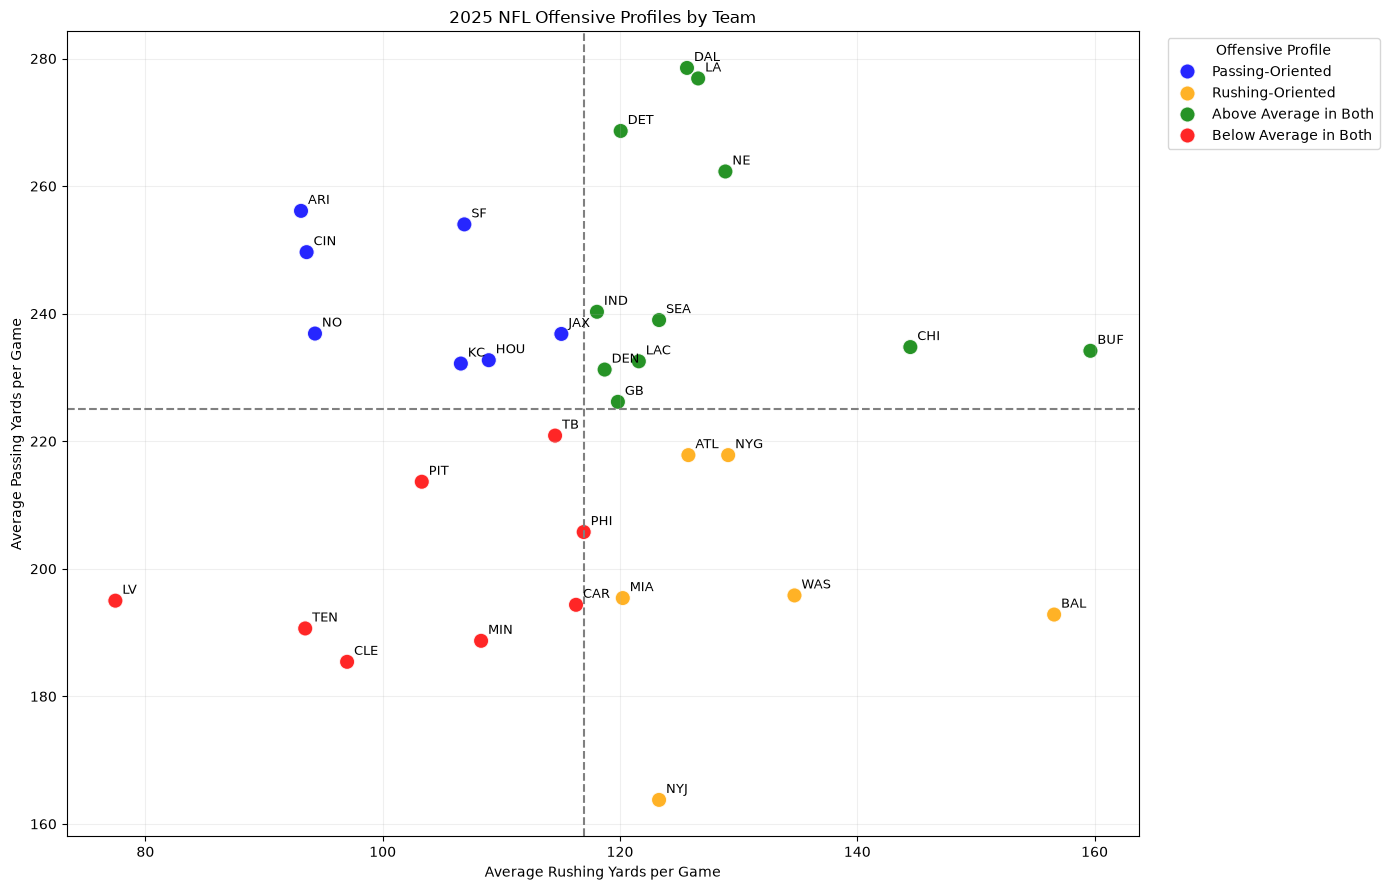

In [8]:
#classifying teams in cateogyrs

conditions = [
    (season_2025["rushing_mean"] >= league_rushing) &
    (season_2025["passing_mean"] >= league_passing),

    (season_2025["rushing_mean"] < league_rushing) &
    (season_2025["passing_mean"] >= league_passing),

    (season_2025["rushing_mean"] >= league_rushing) &
    (season_2025["passing_mean"] < league_passing)
]

categories = [
    "Above Average in Both",
    "Passing-Oriented",
    "Rushing-Oriented",
    
]

season_2025["offensive_profile"] = np.select(
    conditions,
    categories,
    default="Below Average in Both"
)

display(
    season_2025[
        ["team", "rushing_mean", "passing_mean", "offensive_profile"]
    ]
    .sort_values(["offensive_profile", "team"])
    .round(2)
)


# color coded offensive proifle scatterplot
plt.figure(figsize=(14, 9))

sns.scatterplot(
    data=season_2025,
    x="rushing_mean",
    y="passing_mean",
    hue="offensive_profile",
    palette={
        "Above Average in Both": "green",
        "Passing-Oriented": "blue",
        "Rushing-Oriented": "orange",
        "Below Average in Both": "red"
    },
    s=120,
    alpha=0.85
)

# Label each team
for _, row in season_2025.iterrows():
    plt.annotate(
        row["team"],
        (row["rushing_mean"], row["passing_mean"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# League average reference lines
plt.axvline(
    league_rushing,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    league_passing,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

plt.title("2025 NFL Offensive Profiles by Team")
plt.xlabel("Average Rushing Yards per Game")
plt.ylabel("Average Passing Yards per Game")

plt.legend(
    title="Offensive Profile",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Historical Team Peformance
(2000-2025)

In [9]:

# Rank teams within each NFL season

team_season["rushing_rank"] = (
    team_season.groupby("season")["rushing_mean"]
    .rank(ascending=False, method="min")
)

team_season["passing_rank"] = (
    team_season.groupby("season")["passing_mean"]
    .rank(ascending=False, method="min")
)

display(
    team_season[
        [
            "season",
            "team",
             "rushing_mean",
            "rushing_rank",
            "rushing_median",
            "rushing_std",
            "passing_mean",
            "passing_rank",
            "passing_median",
            "passing_std"
        ]
    ].round(2)
)


,season,team,rushing_mean,rushing_rank,rushing_median,rushing_std,passing_mean,passing_rank,passing_median,passing_std
0,2000,ARI,79.88,27.0,80.0,36.47,217.38,16.0,212.0,51.21
1,2000,ATL,75.88,28.0,71.5,31.42,197.88,22.0,186.5,48.12
2,2000,BAL,137.44,5.0,126.5,57.60,193.88,23.0,194.0,62.73
3,2000,BUF,123.07,12.0,120.0,43.39,247.60,8.0,253.0,75.26
4,2000,CAR,74.12,29.0,78.5,40.25,240.62,12.0,238.0,60.38
...,...,...,...,...,...,...,...,...,...,...
825,2025,SEA,123.29,10.0,122.0,41.43,239.00,9.0,244.0,63.00
826,2025,SF,106.88,24.0,91.0,45.55,254.00,6.0,279.0,68.97
827,2025,TB,114.53,21.0,104.0,45.64,220.88,19.0,215.0,76.26
828,2025,TEN,93.47,30.0,82.0,38.45,190.65,29.0,194.0,57.85


### end of classification or ranking of teams by seasons across 26 seasons ###

### start of the league specific stuff ###

In [10]:

league_averages = (
    team_season.groupby("season")
    .agg(
        league_rushing_mean=("rushing_mean", "mean"),
        league_passing_mean=("passing_mean", "mean")
    )
    .reset_index()
)

display(league_averages.round(2))


,season,league_rushing_mean,league_passing_mean
0,2000,112.65,222.35
1,2001,113.29,224.83
2,2002,118.23,230.18
3,2003,117.88,213.94
4,2004,116.71,225.28
5,2005,112.48,218.21
6,2006,117.33,219.24
7,2007,110.95,228.21
8,2008,115.90,224.19
9,2009,116.66,232.26


In [11]:

# Weekly league-wide descriptive statistics

weekly_stats = (
    offense.groupby(["season", "week"])
    .agg(
        team_games=("game_id", "count"),
        rushing_mean=("rushing_yards", "mean"),
        rushing_median=("rushing_yards", "median"),
        passing_mean=("passing_yards", "mean"),
        passing_median=("passing_yards", "median")
    )
    .reset_index()
    .sort_values(["season", "week"])
)

display(weekly_stats.head(20).round(2))




,season,week,team_games,rushing_mean,rushing_median,passing_mean,passing_median
0,2000,1,30,114.53,102.0,208.10,193.5
1,2000,2,30,94.30,97.5,249.20,247.5
2,2000,3,26,107.00,107.5,213.38,189.5
3,2000,4,28,102.25,95.0,223.57,212.5
4,2000,5,28,122.82,133.0,232.18,213.5
5,2000,6,26,108.12,104.0,222.73,230.5
6,2000,7,28,120.00,102.0,231.00,223.0
7,2000,8,28,136.07,124.0,226.82,235.5
8,2000,9,28,108.71,108.5,212.46,211.0
9,2000,10,30,109.47,105.0,228.33,231.5


In [12]:
records = []


for season, season_data in offense.groupby("season"):

    season_data = season_data.sort_values("week")

    for week in sorted(season_data["week"].unique()):

        # Include all team-games through the current week
        games_to_date = season_data.loc[
            season_data["week"] <= week
        ]

        records.append({
            "season": season,
            "week": week,
            "cumulative_team_games": len(games_to_date),

            "rushing_cum_mean":
                games_to_date["rushing_yards"].mean(),

            "rushing_cum_median":
                games_to_date["rushing_yards"].median(),

            "passing_cum_mean":
                games_to_date["passing_yards"].mean(),

            "passing_cum_median":
                games_to_date["passing_yards"].median()
        })

cumulative_stats = pd.DataFrame(records)

# Combine weekly and cumulative statistics
league_progress = weekly_stats.merge(
    cumulative_stats,
    on=["season", "week"],
    validate="one_to_one"
)

display(league_progress.round(2))

,season,week,team_games,rushing_mean,rushing_median,passing_mean,passing_median,cumulative_team_games,rushing_cum_mean,rushing_cum_median,passing_cum_mean,passing_cum_median
0,2000,1,30,114.53,102.0,208.10,193.5,30,114.53,102.0,208.10,193.5
1,2000,2,30,94.30,97.5,249.20,247.5,60,104.42,98.0,228.65,224.5
2,2000,3,26,107.00,107.5,213.38,189.5,86,105.20,100.5,224.03,211.5
3,2000,4,28,102.25,95.0,223.57,212.5,114,104.47,98.0,223.92,211.5
4,2000,5,28,122.82,133.0,232.18,213.5,142,108.09,102.0,225.55,211.5
...,...,...,...,...,...,...,...,...,...,...,...,...
442,2025,14,28,126.11,123.0,215.68,212.5,416,116.19,112.5,226.79,221.5
443,2025,15,32,115.31,113.0,236.03,244.0,448,116.12,112.5,227.45,222.5
444,2025,16,32,125.06,128.5,234.28,215.5,480,116.72,113.5,227.90,222.5
445,2025,17,32,124.31,119.0,210.38,202.5,512,117.19,114.0,226.81,222.0


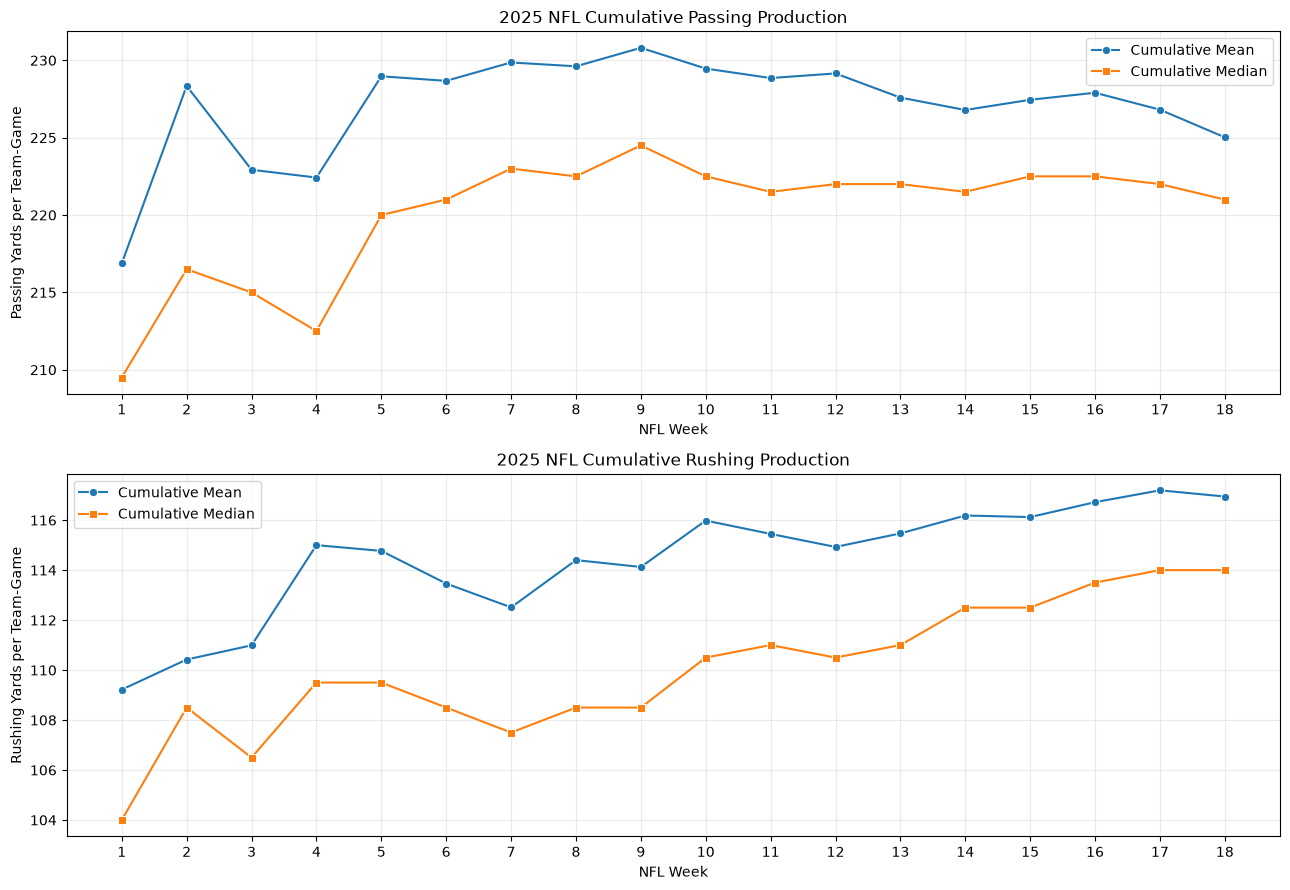

In [13]:
# looking at 2025 just as a rough idea


season_progress = league_progress.loc[
    league_progress["season"] == 2025
]

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Passing
sns.lineplot(
    data=season_progress,
    x="week",
    y="passing_cum_mean",
    marker="o",
    label="Cumulative Mean",
    ax=axes[0]
)

sns.lineplot(
    data=season_progress,
    x="week",
    y="passing_cum_median",
    marker="s",
    label="Cumulative Median",
    ax=axes[0]
)

axes[0].set_title("2025 NFL Cumulative Passing Production")
axes[0].set_ylabel("Passing Yards per Team-Game")

# Rushing
sns.lineplot(
    data=season_progress,
    x="week",
    y="rushing_cum_mean",
    marker="o",
    label="Cumulative Mean",
    ax=axes[1]
)

sns.lineplot(
    data=season_progress,
    x="week",
    y="rushing_cum_median",
    marker="s",
    label="Cumulative Median",
    ax=axes[1]
)

axes[1].set_title("2025 NFL Cumulative Rushing Production")
axes[1].set_ylabel("Rushing Yards per Team-Game")

for ax in axes:
    ax.set_xlabel("NFL Week")
    ax.set_xticks(season_progress["week"])
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()


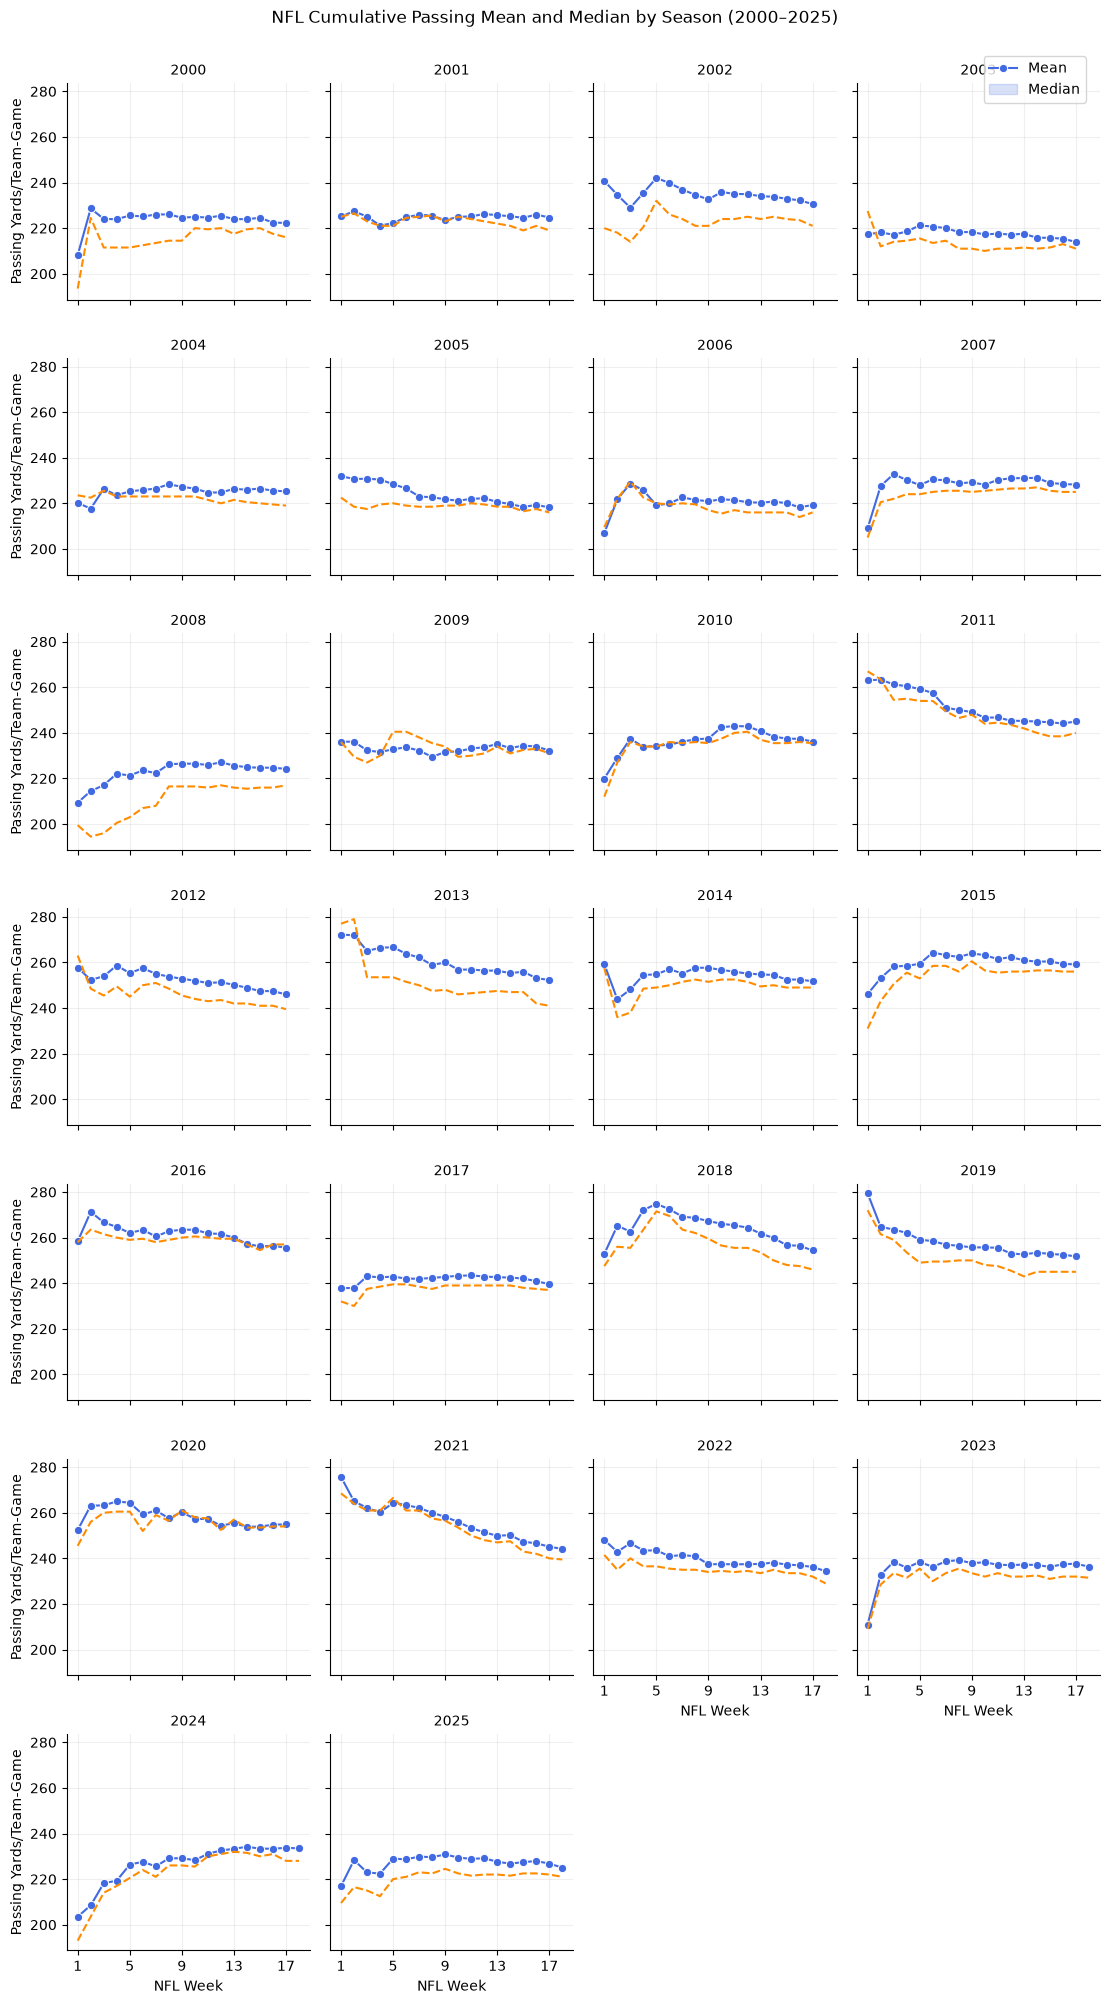

In [14]:
# expanding to 32 teams facet

a = sns.FacetGrid(
    data=league_progress,
    col="season",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

a.map_dataframe(
    sns.lineplot,
    x="week",
    y="passing_cum_mean",
    color="royalblue",
    marker="o",
    label="Mean"
)

a.map_dataframe(
    sns.lineplot,
    x="week",
    y="passing_cum_median",
    color="darkorange",
    linestyle="--",
    label="Median"
)

a.set_axis_labels("NFL Week", "Passing Yards/Team-Game")
a.set_titles("{col_name}")



for ax in a.axes.flat:
    ax.set_xticks([1,5,9,13,17])
    ax.grid(alpha=0.2)

a.fig.legend(
    ["Mean", "Median"],
    loc="upper right",
    bbox_to_anchor=(0.98, 1.0)
)

a.fig.suptitle(
    "NFL Cumulative Passing Mean and Median by Season (2000–2025)",
    y=1.02
)

plt.show()



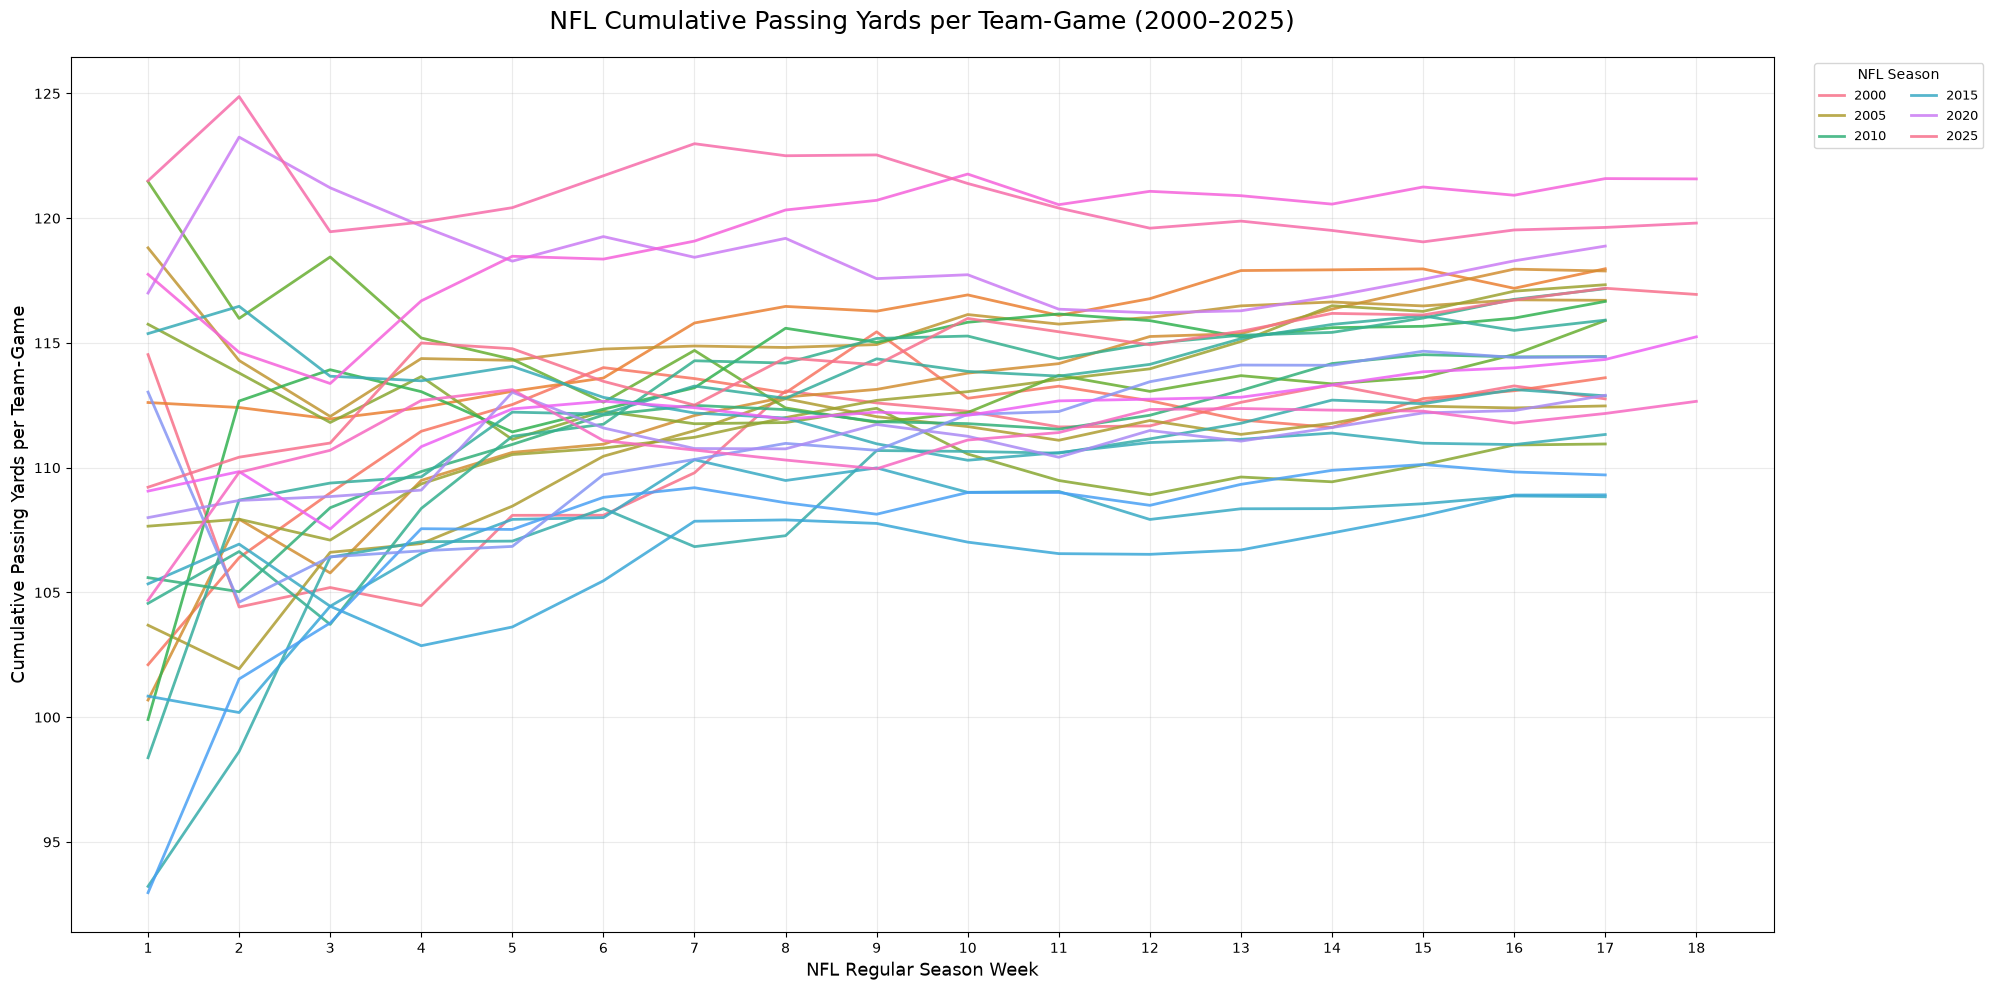

In [ ]:

fig, ax = plt.subplots(figsize=(20, 10))

sns.lineplot(
    data=league_progress,
    x="week",
    y="passing_cum_mean",
    hue="season",
    palette="husl",
    units="season",
    estimator=None,
    linewidth=2,
    alpha=0.85,
    ax=ax
)

ax.set_title(
    "NFL Cumulative Passing Yards per Team-Game (2000–2025)",
    fontsize=18,
    pad=20
)

ax.set_xlabel("NFL Regular Season Week", fontsize=13)
ax.set_ylabel("Cumulative Passing Yards per Team-Game", fontsize=13)

ax.set_xticks(range(1, 19))
ax.grid(alpha=0.25)

ax.legend(
    title="NFL Season",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=9
)

plt.tight_layout()
plt.show()


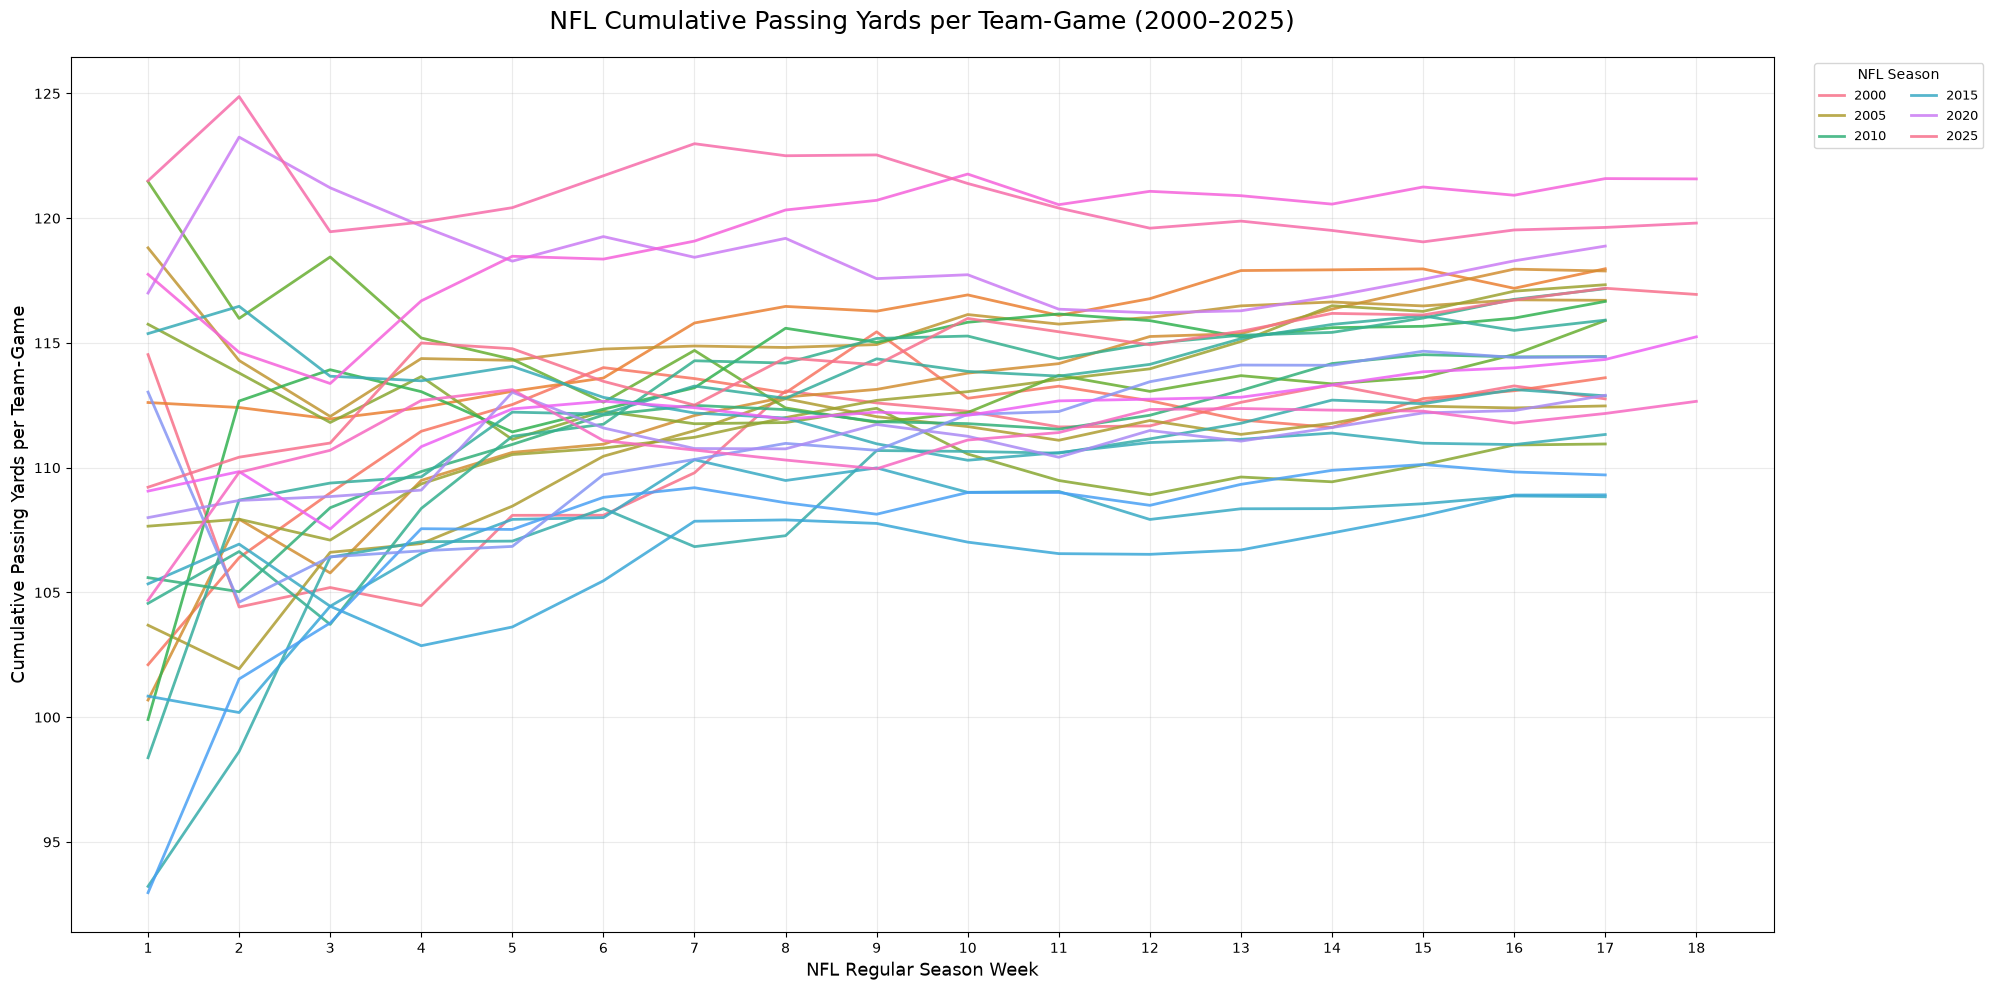

In [22]:
fig, ax = plt.subplots(figsize=(20, 10))

sns.lineplot(
    data=league_progress,
    x="week",
    y="rushing_cum_mean",
    hue="season",
    palette="husl",
    units="season",
    estimator=None,
    linewidth=2,
    alpha=0.85,
    ax=ax
)

ax.set_title(
    "NFL Cumulative Passing Yards per Team-Game (2000–2025)",
    fontsize=18,
    pad=20
)

ax.set_xlabel("NFL Regular Season Week", fontsize=13)
ax.set_ylabel("Cumulative Passing Yards per Team-Game", fontsize=13)

ax.set_xticks(range(1, 19))
ax.grid(alpha=0.25)

ax.legend(
    title="NFL Season",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [16]:

team_season = team_season.merge(
    league_averages,
    on="season",
    how="left",
    validate="many_to_one"
)

# Difference from seasonal league averages
team_season["rushing_diff"] = (
    team_season["rushing_mean"]
    - team_season["league_rushing_mean"]
)

team_season["passing_diff"] = (
    team_season["passing_mean"]
    - team_season["league_passing_mean"]
)

display(
    team_season[
        [
            "season",
            "team",
            "rushing_diff",
            "passing_diff"
        ]
    ].round(2)
)



,season,team,rushing_diff,passing_diff
0,2000,ARI,-32.78,-4.97
1,2000,ATL,-36.78,-24.47
2,2000,BAL,24.78,-28.47
3,2000,BUF,10.41,25.25
4,2000,CAR,-38.53,18.28
...,...,...,...,...
825,2025,SEA,6.35,13.98
826,2025,SF,-10.06,28.98
827,2025,TB,-2.42,-4.14
828,2025,TEN,-23.47,-34.38


#### end of the above league specific section ####

### start of historical team level analysis ###

In [17]:

print("Top 10 Team-Seasons: Passing Yards per Game")

display(
    team_season.nlargest(
        10, "passing_mean"
    )[
        ["season", "team", "passing_mean", "passing_rank"]
    ].round(2)
)

print("Top 10 Team-Seasons: Rushing Yards per Game")

display(
    team_season.nlargest(
        10, "rushing_mean"
    )[
        ["season", "team", "rushing_mean", "rushing_rank"]
    ].round(2)
)


Top 10 Team-Seasons: Passing Yards per Game


,season,team,passing_mean,passing_rank
423,2013,DEN,348.25,1.0
372,2011,NO,347.75,1.0
15,2000,LA,343.25,1.0
603,2018,TB,334.88,1.0
532,2016,NO,328.62,1.0
371,2011,NE,328.56,2.0
500,2015,NO,325.31,1.0
404,2012,NO,324.19,1.0
600,2018,PIT,323.38,2.0
436,2013,NO,322.62,2.0


Top 10 Team-Seasons: Rushing Yards per Game


,season,team,rushing_mean,rushing_rank
608,2019,BAL,206.00,1.0
640,2020,BAL,191.94,1.0
768,2024,BAL,187.59,1.0
191,2006,ATL,183.69,1.0
56,2001,PIT,179.69,1.0
791,2024,PHI,179.29,2.0
707,2022,CHI,177.29,1.0
473,2014,SEA,172.62,1.0
310,2009,NYJ,172.25,1.0
413,2012,WAS,169.31,1.0


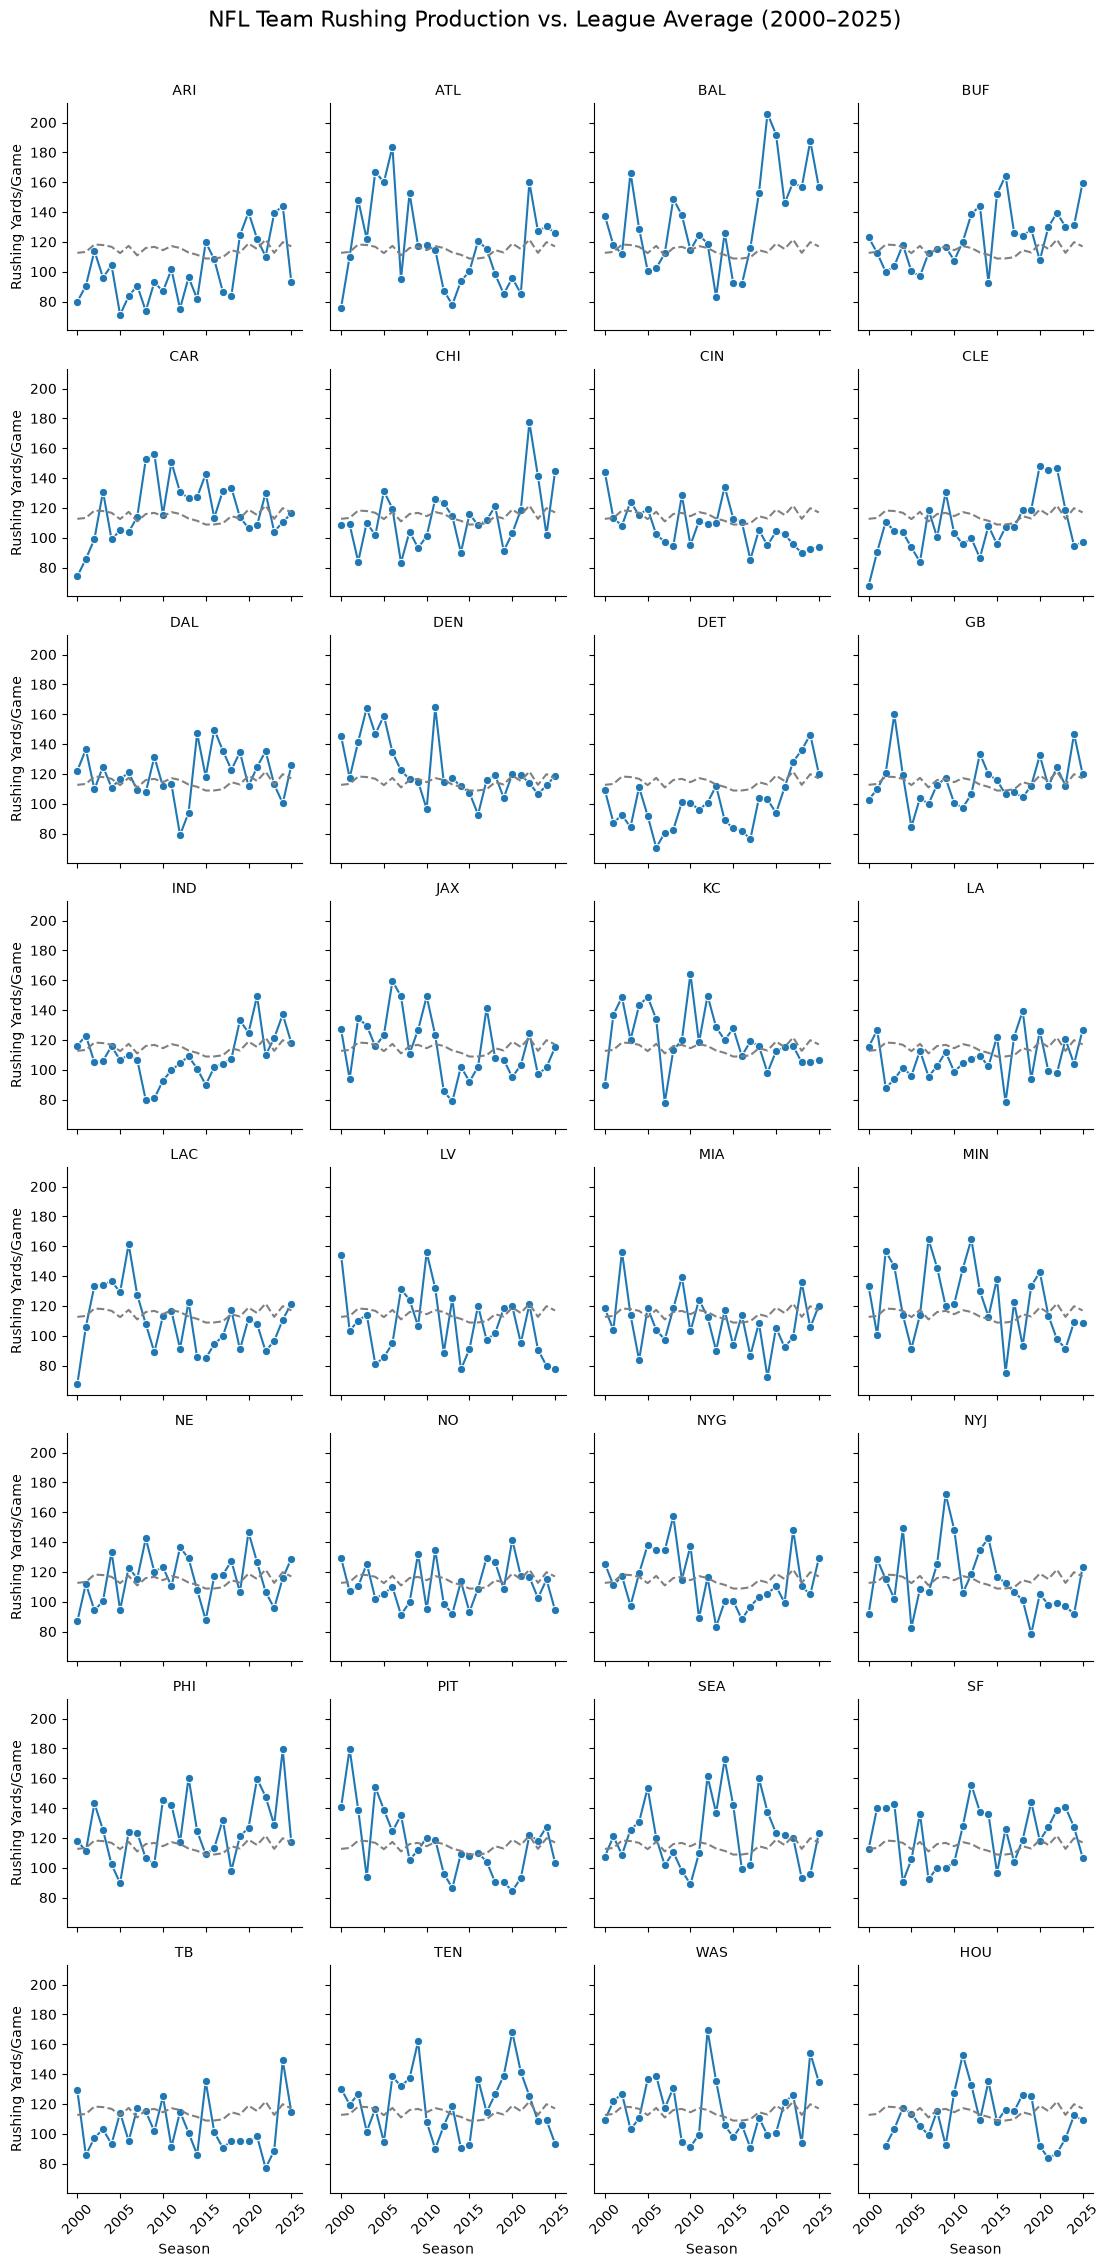

In [18]:

# Historical rushing performance for every NFL team

f = sns.FacetGrid(
    data=team_season,
    col="team",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

# Team rushing averages
f.map_dataframe(
    sns.lineplot,
    x="season",
    y="rushing_mean",
    marker="o"
)

# Add league averages to every subplot
for ax in f.axes.flat:
    ax.plot(
        league_averages["season"],
        league_averages["league_rushing_mean"],
        linestyle="--",
        color="gray",
        linewidth=1.5
    )

f.set_axis_labels(
    "Season",
    "Rushing Yards/Game"
)

f.set_titles("{col_name}")

f.fig.suptitle(
    "NFL Team Rushing Production vs. League Average (2000–2025)",
    y=1.01,
    fontsize=16
)

for ax in f.axes.flat:
    ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025])
    ax.tick_params(axis="x", labelrotation=45)

f.fig.tight_layout()

plt.show()


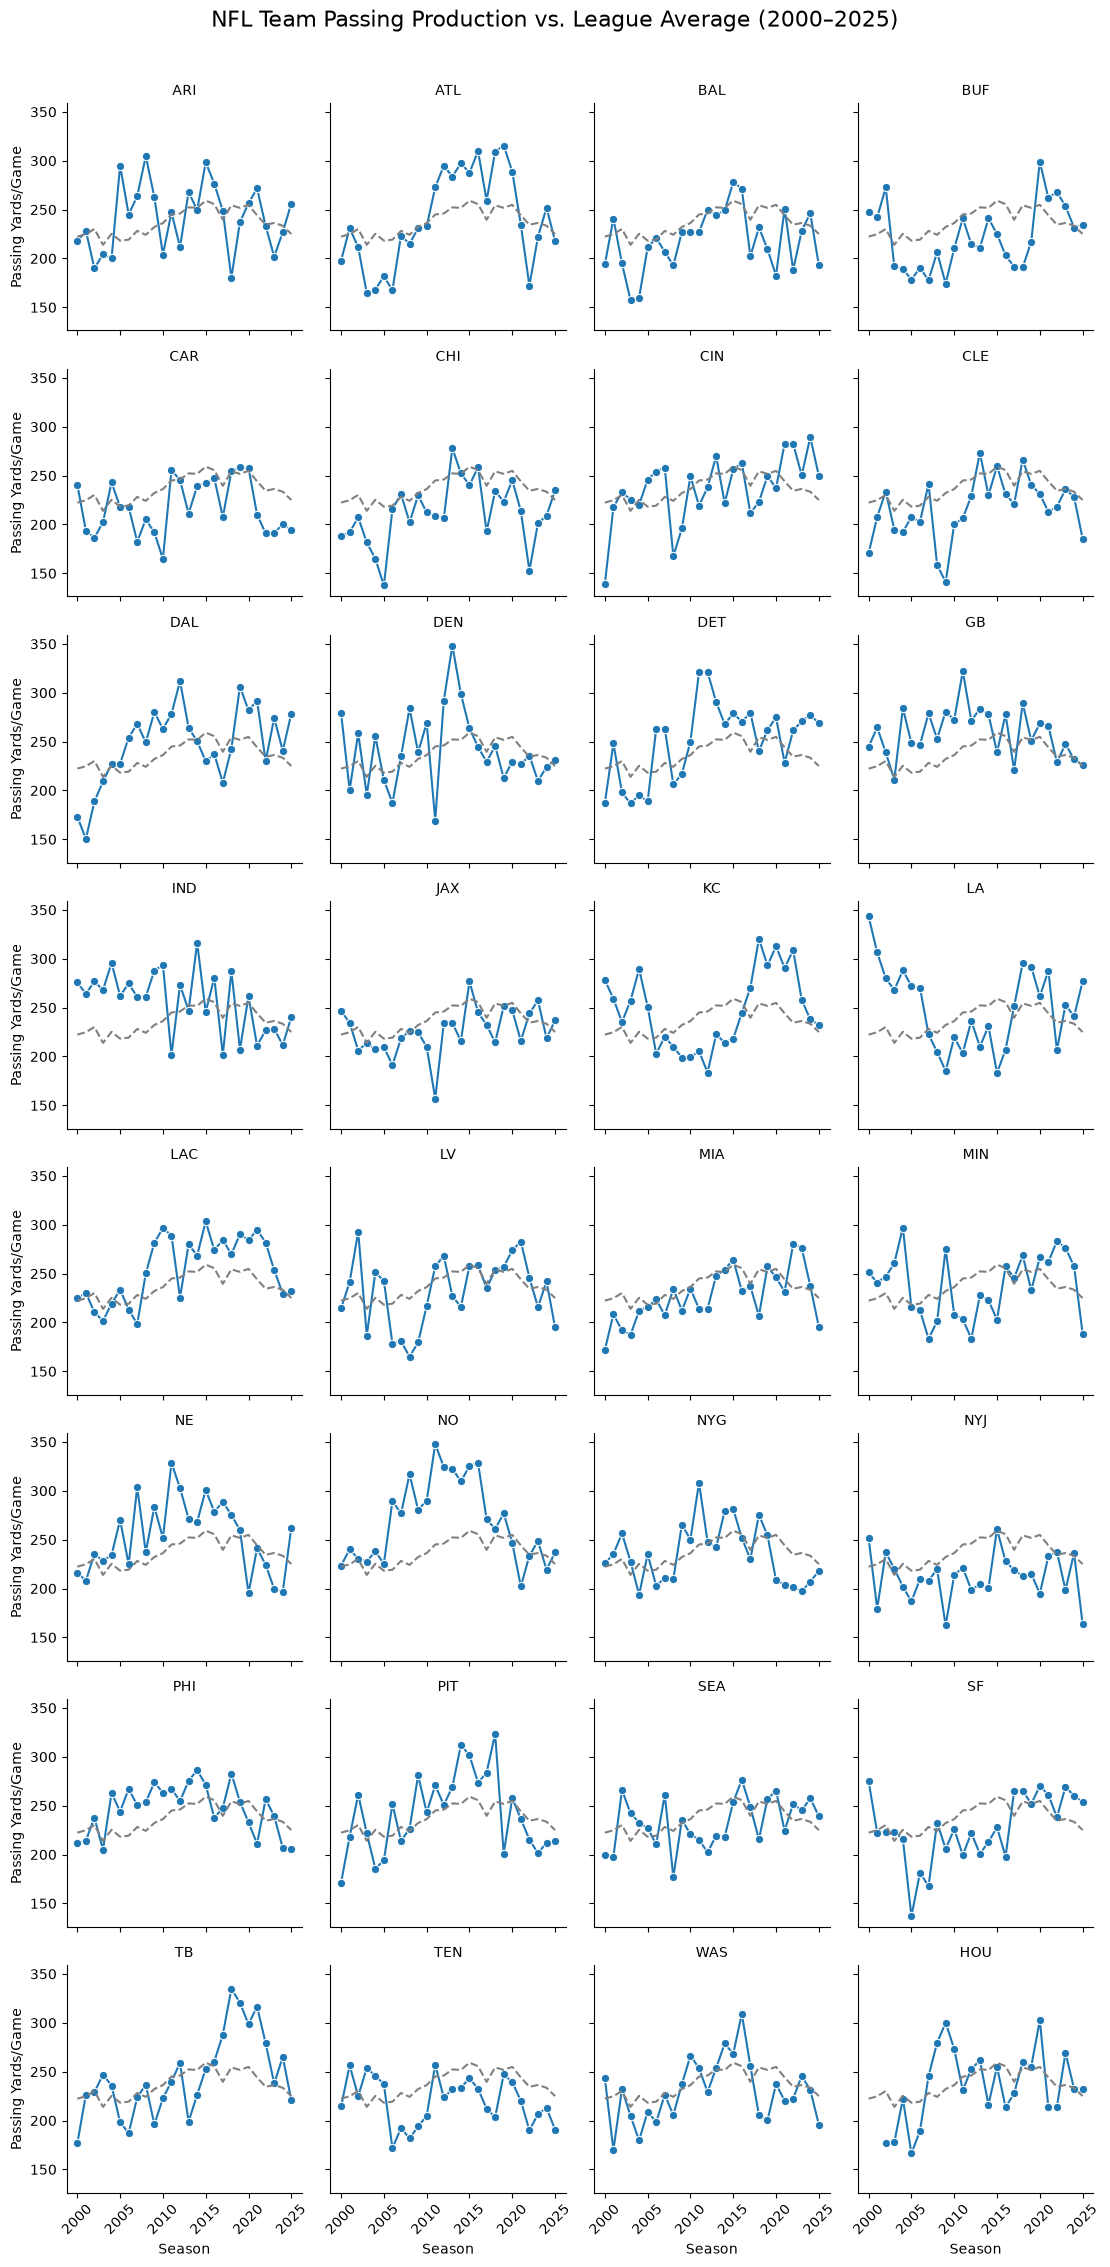

In [19]:

# Historical passing performance for every NFL team

g = sns.FacetGrid(
    data=team_season,
    col="team",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

g.map_dataframe(
    sns.lineplot,
    x="season",
    y="passing_mean",
    marker="o"
)

# League passing averages
for ax in g.axes.flat:
    ax.plot(
        league_averages["season"],
        league_averages["league_passing_mean"],
        linestyle="--",
        color="gray",
        linewidth=1.5
    )

g.set_axis_labels(
    "Season",
    "Passing Yards/Game"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "NFL Team Passing Production vs. League Average (2000–2025)",
    y=1.01,
    fontsize=16
)

for ax in g.axes.flat:
    ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025])
    ax.tick_params(axis="x", labelrotation=45)

g.fig.tight_layout()

plt.show()


In [20]:
# which team was the most consistent in being above their season above the league average in rushing/passing

historical_consistency = (
    team_season.groupby("team")
    .agg(
        seasons=("season", "nunique"),
        rushing_above_avg=("rushing_diff", lambda x: (x > 0).sum()),
        passing_above_avg=("passing_diff", lambda x: (x > 0).sum())
    )
    .reset_index()
)

historical_consistency["rushing_pct"] = (
    historical_consistency["rushing_above_avg"]
    / historical_consistency["seasons"] * 100
)

historical_consistency["passing_pct"] = (
    historical_consistency["passing_above_avg"]
    / historical_consistency["seasons"] * 100
)

display(
    historical_consistency
    .sort_values("passing_pct", ascending=False)
    .round(2)
)

,team,seasons,rushing_above_avg,passing_above_avg,rushing_pct,passing_pct
22,NO,26,9,22,34.62,84.62
11,GB,26,11,20,42.31,76.92
21,NE,26,14,19,53.85,73.08
17,LAC,26,9,19,34.62,73.08
25,PHI,26,19,18,73.08,69.23
10,DET,26,4,17,15.38,65.38
13,IND,26,8,17,30.77,65.38
8,DAL,26,16,16,61.54,61.54
16,LA,26,8,15,30.77,57.69
15,KC,26,16,15,61.54,57.69


# Historical NFL Offensive Production and League-Relative Performance (2000–2025)

## 1. Objective

This analysis examines historical NFL team offensive production across the 2000–2025 regular seasons, focusing on rushing and passing yards per game.

The primary objectives are to:

- Identify the highest-producing individual team-seasons in rushing and passing.
- Evaluate each franchise's offensive production relative to the corresponding season's league average.
- Determine how frequently franchises maintained above-average rushing or passing production.
- Distinguish exceptional single-season performances from sustained historical offensive production.


## 2. Historical Offensive Extremes

### 2.1 Passing Production

The highest passing-yard average in the dataset was recorded by the **2013 Denver Broncos**, who averaged **348.25 passing yards per game**.

The 2011 New Orleans Saints followed closely at **347.75 yards per game**, while the 2000 Rams recorded **343.25 yards per game**.

New Orleans accounted for five of the ten highest passing-yard team-seasons, with appearances in 2011, 2012, 2013, 2015, and 2016.

This concentration of high-production seasons indicates that New Orleans experienced an extended period of exceptional passing output relative to the historical dataset.

Notably, the 2011 New England Patriots and 2013 New Orleans Saints ranked second in passing within their respective seasons, despite appearing among the ten highest historical team-season averages.

### 2.2 Rushing Production

The **2019 Baltimore Ravens** recorded the highest rushing average in the dataset at **206.00 yards per game**.

Baltimore also occupied the second and third positions:

- 2020: 191.94 rushing yards per game.
- 2024: 187.59 rushing yards per game.

Other notable historical performances included the 2006 Atlanta Falcons (183.69), 2001 Pittsburgh Steelers (179.69), and 2024 Philadelphia Eagles (179.29).

Baltimore's three appearances among the top three demonstrate an exceptional concentration of high rushing production during the later portion of the study period.

However, these historical production rankings measure yardage volume rather than offensive efficiency or overall team success.

## 3. Historical Above-Average Offensive Performance

### 3.1 Passing Production

New Orleans demonstrated the highest frequency of above-average passing production among all franchises.

| Franchise | Above-average seasons | Seasons observed | Percentage |
|---|---:|---:|---:|
| New Orleans (NO) | 22 | 26 | 84.62% |
| Green Bay (GB) | 20 | 26 | 76.92% |
| New England (NE) | 19 | 26 | 73.08% |
| LA Chargers (LAC) | 19 | 26 | 73.08% |
| Philadelphia (PHI) | 18 | 26 | 69.23% |
| Detroit (DET) | 17 | 26 | 65.38% |
| Indianapolis (IND) | 17 | 26 | 65.38% |

New Orleans exceeded the league passing average in approximately 85% of observed seasons, supporting its characterization as a historically high-producing passing franchise during this period.

Green Bay, New England, and the Chargers also demonstrated sustained above-average passing production.

Conversely, Chicago, Cleveland, and Tennessee each exceeded the league passing average in only **5 of 26 seasons (19.23%)**.

Baltimore exceeded the passing benchmark in 7 of 26 seasons (26.92%), illustrating that historically strong rushing production does not necessarily coincide with consistently above-average passing yardage.

### 3.2 Rushing Production

Philadelphia and Baltimore recorded the highest frequencies of above-average rushing production.

| Franchise | Above-average seasons | Seasons observed | Percentage |
|---|---:|---:|---:|
| Baltimore (BAL) | 19 | 26 | 73.08% |
| Philadelphia (PHI) | 19 | 26 | 73.08% |
| Denver (DEN) | 17 | 26 | 65.38% |
| Buffalo (BUF) | 17 | 26 | 65.38% |
| Dallas (DAL) | 16 | 26 | 61.54% |
| Kansas City (KC) | 16 | 26 | 61.54% |
| Tennessee (TEN) | 16 | 26 | 61.54% |

Baltimore and Philadelphia each exceeded the league rushing average in approximately 73% of observed seasons.

Baltimore's sustained above-average rushing production is consistent with its multiple appearances among the highest-producing rushing team-seasons in the dataset.

Philadelphia also exhibited a historically strong rushing profile, including its exceptional 2024 season.

At the opposite end, Detroit exceeded the league rushing benchmark in just **4 of 26 seasons (15.38%)**, the lowest frequency in the dataset.

Tampa Bay and Arizona each exceeded the league rushing average in 6 of 26 seasons (23.08%).

## 4. Differences Between Rushing and Passing Profiles

Comparing rushing and passing performance reveals considerable differences in historical offensive specialization.

**New Orleans** exceeded the passing benchmark in 84.62% of seasons but exceeded the rushing benchmark in only 34.62%, representing a substantial difference in its historical production profile.

**Baltimore** displayed the opposite pattern, exceeding the rushing benchmark in 73.08% of seasons but the passing benchmark in only 26.92%.

**Tennessee** similarly exceeded the rushing benchmark in 61.54% of seasons while surpassing the passing benchmark in only 19.23%.

**Philadelphia** demonstrated comparatively balanced historical production, exceeding the rushing benchmark in 73.08% of seasons and the passing benchmark in 69.23%.

These patterns suggest that some franchises maintained considerably stronger historical production in one offensive category than the other.

However, above-average rushing or passing production alone does not establish whether a team strategically favored rushing or passing. Offensive orientation would require further examination of play selection, passing and rushing attempts, and other contextual variables.

## 5. Interpretation and Limitations

Several considerations are important when interpreting these results.

- **League-relative comparisons:** Above-average classifications use each season's league benchmark, making them more appropriate for historical comparisons than a fixed yardage threshold.
- **Equal season weighting:** Each observed season contributes equally to the above-average frequency, regardless of the magnitude by which the team exceeded or fell below the benchmark.
- **Historical variation:** Changes in NFL offensive environments, coaching strategies, rules, and season lengths affect comparisons across different eras.
- **Seasonal rankings:** A team's rank describes its relative production during a particular season and does not necessarily correspond to its historical standing across the entire dataset.
- **Franchise histories:** Historical team identifiers and relocations should be verified to ensure consistent franchise-level interpretation.
- **Offensive efficiency:** Yardage production does not directly measure points scored, efficiency, or the likelihood of winning games.

The above-average season percentage should therefore be interpreted as a measure of the historical frequency of exceeding league yardage benchmarks, not as a direct measure of overall offensive quality or future success.

# end of teams historical offensive average production #####

### start of measuring each teams historical offensive variablity ###


### Historical Offensive Variability (2000–2025)

While average rushing and passing yards provide insight into offensive production, they do not fully capture the consistency of a team's performance. Two teams may exhibit similar seasonal averages while experiencing substantially different levels of game-to-game variation.

This section examines offensive variability across 830 NFL team-seasons from 2000 through 2025. Using standard deviation (SD), coefficient of variation (CV), and Pearson and Spearman correlations, we investigate the relationships between offensive production and dispersion, distinguishing between within-season and between-season variability.

,team,seasons,avg_rushing_ypg,avg_rushing_std,avg_passing_ypg,avg_passing_std
10,DET,26,99.73,40.89,250.63,68.55
12,HOU,24,111.13,42.74,236.22,71.52
0,ARI,26,100.38,43.85,241.49,66.29
29,TB,26,104.17,44.11,245.29,70.01
11,GB,26,114.65,44.41,258.68,69.30
5,CHI,26,112.83,45.46,212.08,65.59
21,NE,26,115.63,45.94,253.29,71.12
16,LA,26,107.47,46.26,249.87,69.10
17,LAC,26,109.48,46.50,254.68,68.44
1,ATL,26,117.96,46.50,240.09,64.66


,team,seasons,rushing_within_sd,passing_within_sd,rushing_between_sd,passing_between_sd
2,BAL,26,52.45,64.45,31.92,31.10
1,ATL,26,46.50,64.66,29.34,48.38
20,MIN,26,47.62,68.71,23.74,32.81
26,PIT,26,48.87,68.01,22.77,40.02
27,SEA,26,48.22,64.00,22.53,24.93
24,NYJ,26,50.11,66.98,22.00,23.86
18,LV,26,49.19,71.94,21.97,35.02
25,PHI,26,52.77,72.85,21.08,25.05
30,TEN,26,51.80,69.64,21.01,24.34
0,ARI,26,43.85,66.29,20.96,34.01


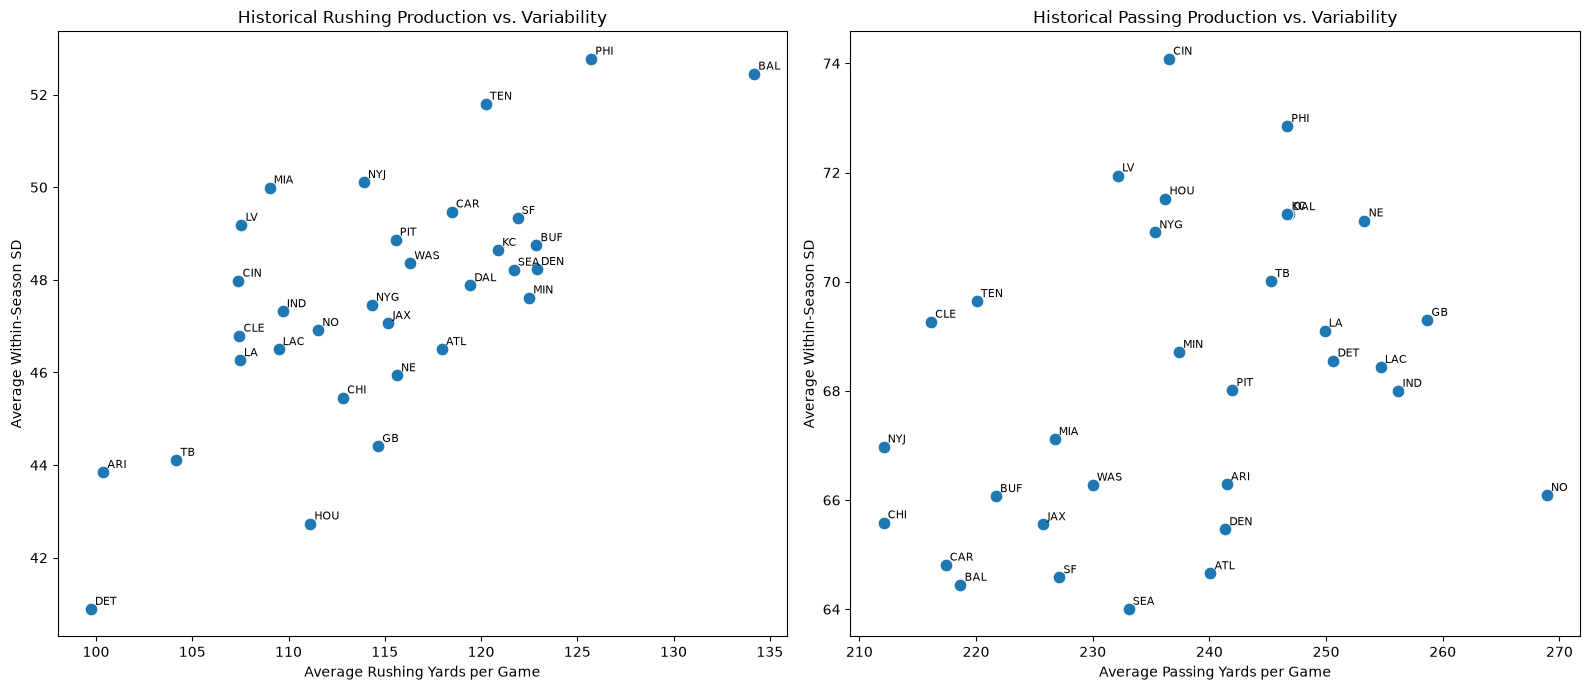

In [25]:

# Summarize each team's historical offensive variability

team_variability = (
    team_season.groupby("team")
    .agg(
        seasons=("season", "nunique"),
        avg_rushing_ypg=("rushing_mean", "mean"),
        avg_rushing_std=("rushing_std", "mean"),
        avg_passing_ypg=("passing_mean", "mean"),
        avg_passing_std=("passing_std", "mean")
    )
    .reset_index()
)

display(
    team_variability
    .sort_values("avg_rushing_std")
    .round(2)
)


#comparing within-season and between-season variability

team_variability_comparison = (
    team_season.groupby("team")
    .agg(
        seasons=("season", "nunique"),

        # Typical game-to-game variability within a season
        rushing_within_sd=("rushing_std", "mean"),
        passing_within_sd=("passing_std", "mean"),

        # Variability in seasonal averages across years
        rushing_between_sd=("rushing_mean", "std"),
        passing_between_sd=("passing_mean", "std")
    )
    .reset_index()
)

display(
    team_variability_comparison
    .sort_values("rushing_between_sd", ascending=False)
    .round(2)
)




fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Rushing
sns.scatterplot(
    data=team_variability,
    x="avg_rushing_ypg",
    y="avg_rushing_std",
    ax=axes[0],
    s=85
)

for _, row in team_variability.iterrows():
    axes[0].annotate(
        row["team"],
        (row["avg_rushing_ypg"], row["avg_rushing_std"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=8
    )

axes[0].set_title("Historical Rushing Production vs. Variability")
axes[0].set_xlabel("Average Rushing Yards per Game")
axes[0].set_ylabel("Average Within-Season SD")

# Passing
sns.scatterplot(
    data=team_variability,
    x="avg_passing_ypg",
    y="avg_passing_std",
    ax=axes[1],
    s=85
)

for _, row in team_variability.iterrows():
    axes[1].annotate(
        row["team"],
        (row["avg_passing_ypg"], row["avg_passing_std"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=8
    )

axes[1].set_title("Historical Passing Production vs. Variability")
axes[1].set_xlabel("Average Passing Yards per Game")
axes[1].set_ylabel("Average Within-Season SD")

plt.tight_layout()
plt.show()


In [ ]:
#### quauntifying these relationships by calcualtin pearson and spearman correlations 
### tema may have differnt average production levels hence why we use the coefficient of variaition

from scipy.stats import pearsonr, spearmanr

comparisons = {
    "Rushing": ("avg_rushing_ypg", "avg_rushing_std"),
    "Passing": ("avg_passing_ypg", "avg_passing_std")
}

for name, (mean_col, std_col) in comparisons.items():

    x = team_variability[mean_col]
    y = team_variability[std_col]

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    print(f"\n{name} Production vs. Variability")
    print(f"Pearson correlation:  {pearson_r:.3f}")
    print(f"Spearman correlation: {spearman_r:.3f}")
    print(f"Pearson p-value:      {pearson_p:.4f}")
    print(f"Spearman p-value:     {spearman_p:.4f}")


# calculating the coeffecient of variation

team_season["rushing_cv"] = (
    team_season["rushing_std"]
    / team_season["rushing_mean"].replace(0, np.nan)
)

team_season["passing_cv"] = (
    team_season["passing_std"]
    / team_season["passing_mean"].replace(0, np.nan)
)

team_cv = (
    team_season.groupby("team")
    .agg(
        avg_rushing_cv=("rushing_cv", "mean"),
        avg_passing_cv=("passing_cv", "mean")
    )
    .reset_index()
)

display(
    team_cv.sort_values("avg_rushing_cv").round(3)

)






Rushing Production vs. Variability
Pearson correlation:  0.692
Spearman correlation: 0.595
Pearson p-value:      0.0000
Spearman p-value:     0.0003

Passing Production vs. Variability
Pearson correlation:  0.326
Spearman correlation: 0.354
Pearson p-value:      0.0689
Spearman p-value:     0.0468


,team,avg_rushing_cv,avg_passing_cv
12,HOU,0.387,0.311
11,GB,0.387,0.270
20,MIN,0.394,0.294
9,DEN,0.395,0.276
2,BAL,0.396,0.299
21,NE,0.399,0.286
1,ATL,0.399,0.278
27,SEA,0.401,0.276
3,BUF,0.401,0.300
15,KC,0.406,0.293


In [ ]:
# Does the rushing correlation remain positive when we calculate it using relative variability rather than absolute standard deviation?

# Combine historical production and relative variability
cv_analysis = team_variability.merge(
    team_cv,
    on="team",
    validate="one_to_one"
)

from scipy.stats import pearsonr, spearmanr

for metric in ["rushing", "passing"]:

    mean_col = f"avg_{metric}_ypg"
    cv_col = f"avg_{metric}_cv"

    pearson_r, pearson_p = pearsonr(
        cv_analysis[mean_col],
        cv_analysis[cv_col]
    )

    spearman_r, spearman_p = spearmanr(
        cv_analysis[mean_col],
        cv_analysis[cv_col]
    )

    print(f"\n{metric.title()} Mean vs. CV")
    print(f"Pearson r:  {pearson_r:.3f} (p={pearson_p:.4f})")
    print(f"Spearman ρ: {spearman_r:.3f} (p={spearman_p:.4f})")


# Rushing production: Higher-producing teams tend to experience greater absolute variation in rushing yards, but lower variation relative to their average production.

# Passing production: The association between production and absolute variability is relatively weak, yet the association between production and relative variability is strongly negative.


Rushing Mean vs. CV
Pearson r:  -0.541 (p=0.0014)
Spearman ρ: -0.576 (p=0.0006)

Passing Mean vs. CV
Pearson r:  -0.783 (p=0.0000)
Spearman ρ: -0.775 (p=0.0000)


In [29]:

from scipy.stats import pearsonr, spearmanr

metrics = ["rushing", "passing"]

for metric in metrics:

    columns = [
        f"{metric}_mean",
        f"{metric}_std",
        f"{metric}_cv"
    ]

    subset = (
        team_season[columns]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    print(f"\n{metric.upper()} — TEAM-SEASON LEVEL")
    print(f"Observations: {len(subset)}")

    for variability in [f"{metric}_std", f"{metric}_cv"]:

        pearson_r, pearson_p = pearsonr(
            subset[f"{metric}_mean"],
            subset[variability]
        )

        spearman_r, spearman_p = spearmanr(
            subset[f"{metric}_mean"],
            subset[variability]
        )

        print(f"\nMean vs. {variability}")
        print(f"Pearson r:   {pearson_r:.3f}")
        print(f"Spearman ρ:  {spearman_r:.3f}")
        print(f"Pearson p:   {pearson_p:.4g}")
        print(f"Spearman p:  {spearman_p:.4g}")



RUSHING — TEAM-SEASON LEVEL
Observations: 830

Mean vs. rushing_std
Pearson r:   0.527
Spearman ρ:  0.511
Pearson p:   1.433e-60
Spearman p:  2.384e-56

Mean vs. rushing_cv
Pearson r:   -0.261
Spearman ρ:  -0.249
Pearson p:   1.972e-14
Spearman p:  3.288e-13

PASSING — TEAM-SEASON LEVEL
Observations: 830

Mean vs. passing_std
Pearson r:   0.239
Spearman ρ:  0.234
Pearson p:   3.076e-12
Spearman p:  9.115e-12

Mean vs. passing_cv
Pearson r:   -0.488
Spearman ρ:  -0.472
Pearson p:   7.175e-51
Spearman p:  3.52e-47


,season,rushing_mean_sd_corr,rushing_mean_cv_corr,passing_mean_sd_corr,passing_mean_cv_corr
0,2000,0.671,-0.133,0.352,-0.462
1,2001,0.389,-0.289,0.376,-0.214
2,2002,0.372,-0.281,0.242,-0.389
3,2003,0.621,-0.128,0.016,-0.675
4,2004,0.390,-0.498,0.526,-0.273
5,2005,0.522,-0.436,0.254,-0.566
6,2006,0.640,-0.243,0.351,-0.422
7,2007,0.726,0.019,0.360,-0.401
8,2008,0.675,-0.120,0.451,-0.567
9,2009,0.658,-0.174,0.052,-0.733


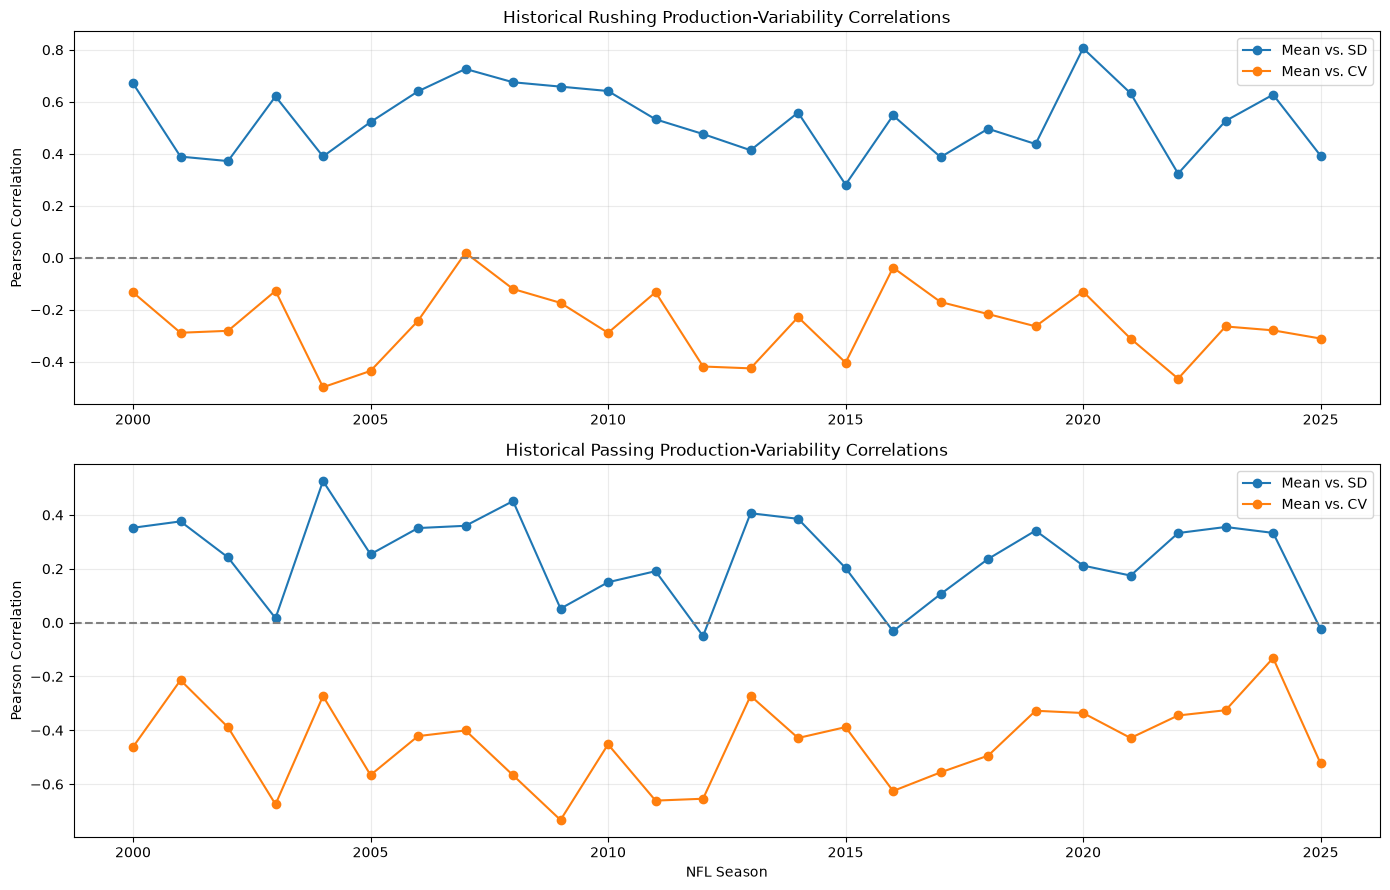

In [31]:
# to wrap up this section of vaariability we ask
# Does the relationship between rushing production and variability remain relatively stable across the 26 seasons, or does it change substantially over time?


# Correlation between rushing/passing production
# and variability within each season

season_correlations = (
    team_season.groupby("season")
    .apply(
        lambda df: pd.Series({
            "rushing_mean_sd_corr":
                df["rushing_mean"].corr(df["rushing_std"]),

            "rushing_mean_cv_corr":
                df["rushing_mean"].corr(df["rushing_cv"]),

            "passing_mean_sd_corr":
                df["passing_mean"].corr(df["passing_std"]),

            "passing_mean_cv_corr":
                df["passing_mean"].corr(df["passing_cv"])
        }),
        include_groups=False
    )
    .reset_index()
)

display(season_correlations.round(3))



fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Rushing relationships
axes[0].plot(
    season_correlations["season"],
    season_correlations["rushing_mean_sd_corr"],
    marker="o",
    label="Mean vs. SD"
)

axes[0].plot(
    season_correlations["season"],
    season_correlations["rushing_mean_cv_corr"],
    marker="o",
    label="Mean vs. CV"
)

axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("Historical Rushing Production-Variability Correlations")
axes[0].set_ylabel("Pearson Correlation")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Passing relationships
axes[1].plot(
    season_correlations["season"],
    season_correlations["passing_mean_sd_corr"],
    marker="o",
    label="Mean vs. SD"
)

axes[1].plot(
    season_correlations["season"],
    season_correlations["passing_mean_cv_corr"],
    marker="o",
    label="Mean vs. CV"
)

axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("Historical Passing Production-Variability Correlations")
axes[1].set_xlabel("NFL Season")
axes[1].set_ylabel("Pearson Correlation")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()



### Conclusion: Historical Offensive Production and Variability

The historical variability analysis revealed several notable differences in the relationship between rushing and passing production and their respective levels of dispersion.

**Rushing production demonstrated a relatively strong positive association with absolute variability.** At the franchise level, the Pearson correlation between mean rushing yards and average within-season standard deviation was **0.692**, declining to **0.527** when evaluated across all 830 team-seasons. This suggests that higher-producing rushing offenses generally exhibited greater absolute game-to-game yardage fluctuations.

Baltimore provides a notable historical example, recording the highest franchise-level average rushing production (**134.18 yards per game**) alongside one of the highest average within-season rushing standard deviations (**52.45 yards**). Baltimore also exhibited the greatest between-season rushing variability (**31.92 yards**), reflecting substantial changes in its average rushing production across the study period.

**Passing production exhibited a weaker relationship with absolute variability.** The Pearson correlation between mean passing production and standard deviation was **0.326** at the franchise level and **0.239** at the team-season level. New Orleans, for example, maintained the highest historical average passing production (**268.92 yards per game**) while demonstrating a comparatively low average within-season passing standard deviation (**66.09 yards**).

When examining relative variability through the coefficient of variation, both rushing and passing production displayed negative relationships. At the team-season level, Pearson correlations were **−0.261 for rushing** and **−0.488 for passing**, indicating that higher average production was associated with lower dispersion relative to the mean. However, these findings must be interpreted cautiously because CV is mathematically dependent on average production.

Historical season-specific correlations further revealed that these relationships were not constant throughout the 2000–2025 period. The relationship between rushing production and absolute variability remained positive across all 26 seasons, while the corresponding passing relationship was generally weaker and occasionally approached zero or became slightly negative.

An important distinction emerged between **within-season and between-season consistency**. A franchise may demonstrate relatively stable game-to-game production within individual seasons while experiencing substantial changes in average offensive output between seasons. Atlanta, for example, recorded particularly high between-season variability in both rushing (**29.34 yards**) and passing (**48.38 yards**), illustrating how historical offensive production can change substantially over time.

Overall, the findings demonstrate that **high offensive production does not necessarily imply consistent or inconsistent performance**. The interpretation depends on whether variability is measured in absolute or relative terms and whether fluctuations are examined within individual seasons or across multiple years.

These results provide a foundation for the next stage of the analysis, which will examine individual teams' offensive performance game by game. By tracking how cumulative means, variability, and league-relative performance evolve throughout a season, subsequent investigations can begin evaluating how reliably historical and early-season statistics describe future offensive outcomes.




### end of historical offensicve production and variability seciton ###